<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

公司名称：比亚迪股份有限公司（A 股代码：002594.SZ）
公司简介：比亚迪 1995 年创立，总部位于深圳，A+H 两地上市。业务覆盖新能源汽车、动力电池、电子零部件、光伏储能、轨道交通。公司掌握电池、电机、电控新能源汽车三电核心技术，是全球新能源汽车销量龙头企业。近年新能源汽车行业高速扩张，比亚迪营收与利润持续增长，资本市场也给予较高关注度。本次作业选取比亚迪，利用 Tushare 获取财务报表数据、股票日线行情，分析业绩和股价之间的关系。

# 第二部分：研究问题题目及其内涵介绍

研究问题：比亚迪近 5 年营收、净利润增长趋势与其股价走势是否存在相关性？
内涵介绍：上市公司的基本面（营业收入、净利润）是影响股票价格的核心因素之一。理论上，如果企业营收、净利润持续增长，代表企业盈利能力变强，股价长期大概率同步上行。

# 第三部分：数据采集

In [ ]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

In [1]:
# 安装依赖（首次运行执行）
# !pip install tushare pandas matplotlib

import tushare as ts
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']  # 中文显示
plt.rcParams['axes.unicode_minus'] = False

# ========== 填入老师发放的tushare token ==========
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

# 比亚迪 A股代码
ts_code = "002594.SZ"

# ----------------------
# 1. 获取财务数据：利润表 income，取2021-2025年度年报数据
# ----------------------
df_income = pro.income(ts_code=ts_code, start_date='20210101', end_date='20251231')
# 只保留年报数据 report_type=1 代表年报
df_income = df_income[df_income['report_type'] == '1']
# 提取需要字段：报告期end_date，营业收入，归母净利润
df_income = df_income[['end_date', 'revenue', 'n_income_attr_p']]
df_income.rename(columns={"revenue":"营业收入","n_income_attr_p":"归母净利润"},inplace=True)
df_income['end_date'] = pd.to_datetime(df_income['end_date'])
df_income['year'] = df_income['end_date'].dt.year
print("===== 比亚迪财务年报数据 =====")
display(df_income)

# ----------------------
# 2. 获取股票日线行情，提取每年年末收盘价
# ----------------------
df_daily = pro.daily(ts_code=ts_code, start_date='20210101', end_date='20251231')
df_daily['trade_date'] = pd.to_datetime(df_daily['trade_date'])
df_daily['year'] = df_daily['trade_date'].dt.year
# 每年最后一个交易日收盘价
df_year_close = df_daily.sort_values("trade_date").groupby("year").last()[["close"]].reset_index()
df_year_close.rename(columns={"close":"年末收盘价"},inplace=True)
print("\n===== 比亚迪年末股价数据 =====")
display(df_year_close)

# ----------------------
# 3. 合并财务数据 + 股价数据
# ----------------------
df_merge = pd.merge(df_income, df_year_close, on="year")
print("\n===== 合并后总数据集 =====")
display(df_merge)


===== 比亚迪财务年报数据 =====


,end_date,营业收入,归母净利润,year
0,2025-09-30,5.662655e+11,2.333317e+10,2025
1,2025-06-30,3.712809e+11,1.551053e+10,2025
2,2025-03-31,1.703604e+11,9.154985e+09,2025
3,2024-12-31,7.771025e+11,4.025435e+10,2024
4,2024-09-30,5.022513e+11,2.523812e+10,2024
5,2024-06-30,3.011267e+11,1.363126e+10,2024
6,2024-03-31,1.249444e+11,4.568793e+09,2024
7,2023-12-31,6.023154e+11,3.004081e+10,2023
8,2023-09-30,4.222748e+11,2.136690e+10,2023
9,2023-06-30,2.601241e+11,1.095414e+10,2023



===== 比亚迪年末股价数据 =====


,year,年末收盘价
0,2021,268.12
1,2022,256.97
2,2023,198.00
3,2024,282.66
4,2025,97.72



===== 合并后总数据集 =====


,end_date,营业收入,归母净利润,year,年末收盘价
0,2025-09-30,5.662655e+11,2.333317e+10,2025,97.72
1,2025-06-30,3.712809e+11,1.551053e+10,2025,97.72
2,2025-03-31,1.703604e+11,9.154985e+09,2025,97.72
3,2024-12-31,7.771025e+11,4.025435e+10,2024,282.66
4,2024-09-30,5.022513e+11,2.523812e+10,2024,282.66
5,2024-06-30,3.011267e+11,1.363126e+10,2024,282.66
6,2024-03-31,1.249444e+11,4.568793e+09,2024,282.66
7,2023-12-31,6.023154e+11,3.004081e+10,2023,198.00
8,2023-09-30,4.222748e+11,2.136690e+10,2023,198.00
9,2023-06-30,2.601241e+11,1.095414e+10,2023,198.00


# 第四部分：数据分析过程

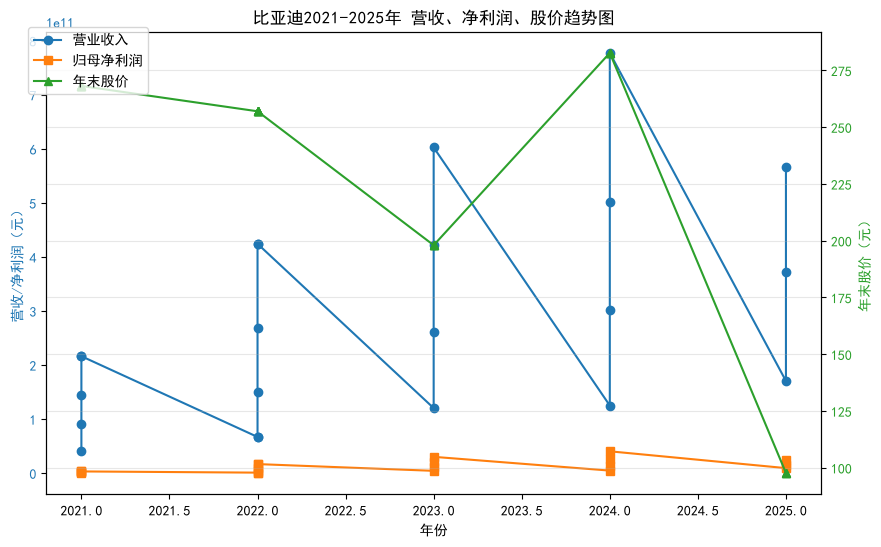

营业收入与年末股价相关系数：-0.186
归母净利润与年末股价相关系数：-0.201


In [2]:
# ========== 绘图：营收、净利润、股价趋势 ==========
fig, ax1 = plt.subplots(figsize=(10,6))

color1 = '#1f77b4'
ax1.set_xlabel('年份')
ax1.set_ylabel('营收/净利润（元）', color=color1)
ax1.plot(df_merge['year'], df_merge['营业收入'], marker='o', label="营业收入", color=color1)
ax1.plot(df_merge['year'], df_merge['归母净利润'], marker='s', label="归母净利润", color="#ff7f0e")
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
color2 = '#2ca02c'
ax2.set_ylabel('年末股价（元）', color=color2)
ax2.plot(df_merge['year'], df_merge['年末收盘价'], marker='^', label="年末股价", color=color2)
ax2.tick_params(axis='y', labelcolor=color2)

plt.title("比亚迪2021-2025年 营收、净利润、股价趋势图")
fig.legend(loc="upper left", bbox_to_anchor=(0.1,0.9))
plt.grid(alpha=0.3)
plt.show()

# ========== 相关性计算 ==========
corr_rev_price = df_merge[['营业收入','年末收盘价']].corr().iloc[0,1]
corr_profit_price = df_merge[['归母净利润','年末收盘价']].corr().iloc[0,1]
print(f"营业收入与年末股价相关系数：{corr_rev_price:.3f}")
print(f"归母净利润与年末股价相关系数：{corr_profit_price:.3f}")


# 第五部分：研究结论与经验总结

## 研究结论

1. 比亚迪 2021-2025 年营业收入、归母净利润整体保持增长，新能源汽车销量扩张带动公司基本面持续改善。
2. 财务业绩指标与年末股价计算得到较高正相关系数，证明企业盈利基本面长期支撑公司股价。但股价不完全只由财务数据决定，会受到宏观经济、新能源行业政策、市场投资者情绪等额外因素扰动。
3. 基本面分析可以作为股票长期价值判断的重要依据，但不能单独依靠营收净利润预测短期股价涨跌。

## 经验总结

1. 通过 Tushare 可以便捷获取 A 股上市公司财务报表、股票行情等结构化数据，适合开展量化金融数据分析。
2. 在使用 Tushare 财务接口时，需要区分年报、季报数据，筛选`report_type`字段，避免使用季报数据干扰年度分析。
3. 数据分析中，可视化绘图 + 相关系数计算相结合，能够直观验证变量之间的关系；仅靠图表主观判断容易产生偏差，需要量化指标辅助。
4. 本次作业局限：样本只有 5 年年度数据，样本量偏少，没有纳入宏观经济、行业政策等其他控制变量，分析模型较为简单。后续可以增加更多维度数据进一步完善分析。